# AyatQu: Pipeline Temu Kembali Ayat Al-Qur'an Berbasis Topik

**Pengembangan Chatbot AyatQu untuk Pencarian Ayat Al-Qur'an Berbasis Topik Menggunakan Retrieval-Augmented Generation dengan Perbandingan TF-IDF dan BM25 serta Perluasan Kueri Bahasa Awam**

Notebook ini mencakup seluruh tahap sebelum aplikasi Streamlit dibuat:

| Bagian | Isi |
|---|---|
| 1 | Setup dan pemuatan data |
| 2 | Preprocessing (empat konfigurasi) |
| 3 | Indexing TF-IDF dan BM25 (BM25 diimplementasikan sendiri) |
| 4 | Query expansion dengan kamus istilah awam |
| 5 | Data evaluasi: kueri uji dan kunci jawaban (qrels) |
| 6 | Metrik evaluasi beserta uji kebenarannya |
| 7 | Eksperimen: ablasi preprocessing, tuning parameter, perbandingan sistem |
| 8 | Uji signifikansi Wilcoxon, analisis error |
| 9 | Ambang skor untuk jawaban "tidak ditemukan" |
| 10 | Komponen RAG: prompt, guardrail, validasi keluaran, rubrik chatbot |
| 11 | Ekspor konfigurasi terbaik untuk aplikasi |

**Aturan utama proyek:** kolom `teks_arab` dan `terjemahan` tidak pernah diubah. Semua pembersihan, stopword, dan stemming hanya dilakukan pada salinan khusus indexing.

**Cara menjalankan:** jalankan sel dari atas ke bawah (`Run All`). Notebook ini diharapkan dijalankan dari folder `ayatqu/` yang berisi `data/`, dan akan memindahkan direktori kerja otomatis bila dijalankan dari subfolder.

## 1. Setup dan Pemuatan Data

In [5]:
# Jika library belum terpasang, jalankan sekali di terminal:
#   pip install -r requirements.txt
# PySastrawi wajib untuk konfigurasi stemming (C3 dan C4).

import json, re, math, os, warnings, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

# Pastikan direktori kerja adalah root proyek (yang memiliki folder data/raw)
if not Path("data/raw").exists() and Path("../data/raw").exists():
    os.chdir("..")
assert Path("data/raw").exists(), "Jalankan notebook dari folder ayatqu/ yang berisi data/raw"

for d in ["data/processed", "data/eval", "figures", "models", "outputs"]:
    Path(d).mkdir(parents=True, exist_ok=True)

try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    SASTRAWI_OK = True
except ImportError:
    SASTRAWI_OK = False
    print("PERINGATAN: PySastrawi belum terpasang. Konfigurasi stemming (C3, C4) dilewati.")
    print("Pasang dengan: pip install PySastrawi")

print("Direktori kerja:", Path.cwd())
print("Sastrawi tersedia:", SASTRAWI_OK)

Direktori kerja: c:\Users\USER\Downloads\ayatqu_project (1)\ayatqu
Sastrawi tersedia: True


In [6]:
MASTER = Path("data/processed/quran_master.csv")
df = pd.read_csv(MASTER, encoding="utf-8-sig", dtype=str, keep_default_na=False)
for col in ["id", "surah_no", "ayat_no"]:
    df[col] = df[col].astype(int)

# Validasi dasar data
assert len(df) == 6236, f"Jumlah ayat {len(df)}, seharusnya 6236"
assert df["surah_no"].nunique() == 114
assert not df.duplicated(["surah_no", "ayat_no"]).any()
assert df["terjemahan"].str.strip().ne("").all()
arab_kosong = (df["teks_arab"].str.strip() == "").sum()
if arab_kosong:
    print(f"PERINGATAN: {arab_kosong} baris teks_arab kosong. Jalankan src/build_dataset.py dengan quran-uthmani.txt.")

# Salinan untuk membuktikan bahwa kolom tampilan tidak pernah berubah
DISPLAY_SNAPSHOT = df[["id", "teks_arab", "terjemahan"]].copy()

print(f"Ayat: {len(df):,} | Surah: {df['surah_no'].nunique()} | Kolom: {list(df.columns)}")
df.sample(3, random_state=SEED)[["id", "surah_nama", "ayat_no", "terjemahan"]]

Ayat: 6,236 | Surah: 114 | Kolom: ['id', 'surah_no', 'surah_nama', 'ayat_no', 'teks_arab', 'terjemahan']


,id,surah_nama,ayat_no,terjemahan
599,600,An-Nisa',107,Dan janganlah kamu berdebat (untuk membela) orang-orang yang mengkhianati dirinya. Sesungguhnya Allah tidak menyukai...
1844,1845,Al-Hijr,43,Dan sesungguhnya Jahannam itu benar-benar tempat yang telah diancamkan kepada mereka (pengikut-pengikut syaitan) sem...
3107,3108,Asy-Syu'ara',176,Penduduk Aikah telah mendustakan rasul-rasul;


## 2. Preprocessing

Pembersihan dilakukan hanya pada **salinan** terjemahan untuk keperluan indexing, dan juga pada kueri pengguna dengan fungsi yang sama.

Langkah yang dilakukan:

1. **Perbaikan typo huruf "I" kapital** yang menggantikan huruf "l" kecil (contoh `SuIaiman` seharusnya `Sulaiman`). Typo ini ada di sumber Tanzil dan hanya diperbaiki pada salinan indexing.
2. **Case folding** ke huruf kecil.
3. **Pembersihan**: hapus apostrof, ubah tanda hubung menjadi spasi (agar `orang-orang` menjadi dua token), hapus angka dan tanda baca. Kata di dalam tanda kurung tetap dipertahankan karena sering memuat kata kunci penting.
4. **Tokenisasi** berbasis spasi.
5. **Stopword removal** dengan daftar yang disusun sendiri. Kata negasi (`tidak`, `bukan`, `jangan`, `tiada`, `tanpa`, `belum`) sengaja **tidak** dibuang karena maknanya penting.
6. **Stemming** dengan Sastrawi. Hasil stem disimpan per kata ke cache agar tidak perlu diulang.

Khusus **kueri**, kata penunjuk seperti `ayat`, `tentang`, dan `mengenai` dibuang karena hanya meta-kata, bukan topik.

In [7]:
STOPWORDS = set("""
yang dan di ke dari pada untuk dengan atau akan telah sudah adalah ialah itu ini maka jika apabila karena
agar supaya sebagai oleh dalam saja pula lagi kepada para bagi hanya serta tetapi tetapilah sedang sedangkan
kamu kami kita mereka dia ia aku engkau kalian nya lah kah pun juga yaitu yakni ketika sebelum sesudah setelah
hingga sampai antara bahwa sehingga seperti sebagaimana dapat bisa harus mau ada dengannya padanya olehnya
atasnya bagimu bagi mereka mu ku dll dsb sebab walau walaupun meskipun namun kecuali selain seraya sambil
""".split())
NEGASI = {"tidak", "bukan", "jangan", "tiada", "tanpa", "belum"}
STOPWORDS -= NEGASI

# Kata meta pada kueri pengguna. Tidak dibuang dari korpus, hanya dari kueri.
QUERY_STOPWORDS = set("""
ayat tentang mengenai soal terkait quran alquran al qur an surah surat yang bikin apa ya dong nih
tolong carikan cari bagaimana gimana bisa ada
""".split())

CONFIGS = {
    "C1_dasar":     {"stop": False, "stem": False},
    "C2_stopword":  {"stop": True,  "stem": False},
    "C3_stem":      {"stop": False, "stem": True},
    "C4_stop_stem": {"stop": True,  "stem": True},
}
AVAILABLE_CONFIGS = [c for c, v in CONFIGS.items() if (not v["stem"]) or SASTRAWI_OK]
print("Konfigurasi yang bisa dijalankan:", AVAILABLE_CONFIGS)

_TYPO_I = re.compile(r"(?<=[a-z])I(?=[a-z])")

def clean_text(text):
    """Case folding, perbaikan typo, dan pembersihan karakter."""
    t = _TYPO_I.sub("l", text)
    t = t.lower()
    t = t.replace("'", "").replace("\u2019", "").replace("`", "")
    t = re.sub(r"[-\u2010-\u2015]", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# Stemmer dengan cache per kata (lebih cepat dan hasilnya bisa disimpan)
STEM_CACHE_PATH = Path("data/processed/stem_cache.json")
_STEM_CACHE = json.loads(STEM_CACHE_PATH.read_text(encoding="utf-8")) if STEM_CACHE_PATH.exists() else {}
_stemmer = StemmerFactory().create_stemmer() if SASTRAWI_OK else None

def stem_word(w):
    if w not in _STEM_CACHE:
        _STEM_CACHE[w] = _stemmer.stem(w)
    return _STEM_CACHE[w]

def preprocess(text, stop=False, stem=False, is_query=False):
    toks = clean_text(text).split()
    if is_query:
        toks = [t for t in toks if t not in QUERY_STOPWORDS]
    if stop:
        toks = [t for t in toks if t not in STOPWORDS]
    if stem:
        toks = [stem_word(t) for t in toks]
    return toks

contoh = "Sesungguhnya Allah beserta orang-orang yang sabar. (Al Baqarah: 153) SuIaiman"
print("Asli     :", contoh)
for nama, cfg in CONFIGS.items():
    if nama in AVAILABLE_CONFIGS:
        print(f"{nama:13s}:", " ".join(preprocess(contoh, **cfg)))

Konfigurasi yang bisa dijalankan: ['C1_dasar', 'C2_stopword', 'C3_stem', 'C4_stop_stem']
Asli     : Sesungguhnya Allah beserta orang-orang yang sabar. (Al Baqarah: 153) SuIaiman
C1_dasar     : sesungguhnya allah beserta orang orang yang sabar al baqarah sulaiman
C2_stopword  : sesungguhnya allah beserta orang orang sabar al baqarah sulaiman
C3_stem      : sungguh allah serta orang orang yang sabar al baqarah sulaiman
C4_stop_stem : sungguh allah serta orang orang sabar al baqarah sulaiman


In [8]:
# Audit typo di sumber: kata yang mengandung huruf I kapital di tengah kata kecil
typo_rows = []
for _, r in df.iterrows():
    for m in re.findall(r"\b\w*[a-z]I[a-z]\w*\b", r["terjemahan"]):
        typo_rows.append({"id": r["id"], "surah:ayat": f"{r['surah_no']}:{r['ayat_no']}", "kata_asli": m,
                          "diperbaiki_jadi": _TYPO_I.sub("l", m)})
typo_df = pd.DataFrame(typo_rows)
print(f"Typo ditemukan di sumber: {len(typo_df)} kata (hanya diperbaiki pada salinan indexing)")
display(typo_df)

Typo ditemukan di sumber: 16 kata (hanya diperbaiki pada salinan indexing)


,id,surah:ayat,kata_asli,diperbaiki_jadi
0,1093,7:139,seIalu,selalu
1,1232,8:72,pertoIongan,pertolongan
2,1435,10:71,bacakanIah,bacakanlah
3,1453,10:89,AlIah,Allah
4,1472,10:108,teIah,telah
5,1986,16:85,puIa,pula
6,2286,19:36,sembahIah,sembahlah
7,2489,21:6,sebeIum,sebelum
8,2494,21:11,teIah,telah
9,2497,21:14,zaIim,zalim


In [9]:
# Bangun token untuk semua konfigurasi
def build_tokens(texts, config):
    cfg = CONFIGS[config]
    return [preprocess(t, stop=cfg["stop"], stem=cfg["stem"]) for t in texts]

TOKENS = {}
for c in AVAILABLE_CONFIGS:
    TOKENS[c] = build_tokens(df["terjemahan"], c)

if SASTRAWI_OK:
    STEM_CACHE_PATH.write_text(json.dumps(_STEM_CACHE, ensure_ascii=False), encoding="utf-8")

# Simpan hasil ke CSV (kolom baru khusus indexing, kolom asli tetap)
proc = df[["id", "surah_no", "surah_nama", "ayat_no"]].copy()
for c in AVAILABLE_CONFIGS:
    proc[c] = [" ".join(t) for t in TOKENS[c]]
proc.to_csv("data/processed/quran_processed.csv", index=False, encoding="utf-8-sig")

# Bukti bahwa teks tampilan tidak berubah
assert df["teks_arab"].equals(DISPLAY_SNAPSHOT["teks_arab"])
assert df["terjemahan"].equals(DISPLAY_SNAPSHOT["terjemahan"])
print("OK: kolom teks_arab dan terjemahan tidak berubah.")

stat = pd.DataFrame({
    "konfigurasi": AVAILABLE_CONFIGS,
    "rata_rata_token_per_ayat": [np.mean([len(t) for t in TOKENS[c]]) for c in AVAILABLE_CONFIGS],
    "ukuran_kosakata": [len({w for t in TOKENS[c] for w in t}) for c in AVAILABLE_CONFIGS],
})
display(stat.round(2))

OK: kolom teks_arab dan terjemahan tidak berubah.


,konfigurasi,rata_rata_token_per_ayat,ukuran_kosakata
0,C1_dasar,25.75,6791
1,C2_stopword,15.47,6707
2,C3_stem,25.75,2742
3,C4_stop_stem,15.47,2710


## 3. Indexing dan Ranking: TF-IDF dan BM25

Dua metode ranking diimplementasikan dan dibandingkan:

- **TF-IDF + cosine similarity.** Bobot dokumen memakai TF sublinear (`1 + log tf`) dan IDF ter-smooth dari scikit-learn, dinormalisasi L2.
- **BM25** (Robertson dan Zaragoza, 2009) diimplementasikan sendiri dengan IDF varian Lucene `log(1 + (N - n + 0.5) / (n + 0.5))` yang tidak pernah bernilai negatif. Parameter awal `k1 = 1.5` dan `b = 0.75`.

Kedua indeks menerima **bobot kueri per istilah**, sehingga istilah hasil ekspansi bisa diberi bobot lebih kecil daripada kata asli dari pengguna.

In [10]:
class BM25Index:
    """BM25 (varian Lucene) berbasis matriks sparse CSC."""
    def __init__(self, docs_tokens, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        docs_str = [" ".join(t) for t in docs_tokens]
        self.cv = CountVectorizer(analyzer=str.split)
        X = self.cv.fit_transform(docs_str).tocsc().astype(np.float64)
        self.X = X
        self.vocab = self.cv.vocabulary_
        self.N = X.shape[0]
        self.dl = np.asarray(X.sum(axis=1)).ravel()
        self.avgdl = self.dl.mean()
        dfreq = np.asarray((X > 0).sum(axis=0)).ravel()
        self.idf = np.log(1.0 + (self.N - dfreq + 0.5) / (dfreq + 0.5))
        # Kata yang tidak ada di korpus diperlakukan sebagai kata sangat langka (df = 0)
        self.idf_oov = np.log(1.0 + (self.N + 0.5) / 0.5)

    def set_params(self, k1, b):
        self.k1, self.b = k1, b

    def score(self, qweights):
        """qweights: dict token -> bobot. Mengembalikan skor BM25 untuk semua dokumen."""
        scores = np.zeros(self.N)
        norm = self.k1 * (1.0 - self.b + self.b * self.dl / self.avgdl)
        for t, w in qweights.items():
            j = self.vocab.get(t)
            if j is None:
                continue
            s, e = self.X.indptr[j], self.X.indptr[j + 1]
            rows, tf = self.X.indices[s:e], self.X.data[s:e]
            scores[rows] += w * self.idf[j] * tf * (self.k1 + 1.0) / (tf + norm[rows])
        return scores

    def max_score(self, qweights):
        """
        Batas atas skor teoritis (tf menuju tak hingga), dipakai untuk menormalkan skor.
        Kata kueri yang tidak ada di korpus tetap dihitung (sebagai kata sangat langka),
        sehingga kueri yang sebagian besar katanya tidak dikenal mendapat skor ternormalisasi rendah.
        """
        total = 0.0
        for t, w in qweights.items():
            idf = self.idf[self.vocab[t]] if t in self.vocab else self.idf_oov
            total += w * idf * (self.k1 + 1.0)
        return total


class TFIDFIndex:
    """TF-IDF sublinear dengan cosine similarity."""
    def __init__(self, docs_tokens):
        docs_str = [" ".join(t) for t in docs_tokens]
        self.vec = TfidfVectorizer(analyzer=str.split, sublinear_tf=True, norm="l2")
        self.M = self.vec.fit_transform(docs_str).tocsr()
        self.vocab = self.vec.vocabulary_
        self.idf = self.vec.idf_
        self.N = self.M.shape[0]

    def score(self, qweights):
        cols, vals = [], []
        for t, w in qweights.items():
            j = self.vocab.get(t)
            if j is not None:
                cols.append(j)
                vals.append(w * self.idf[j])
        if not cols:
            return np.zeros(self.N)
        q = np.zeros(len(self.vocab))
        q[cols] = vals
        q /= np.linalg.norm(q)
        return np.asarray(self.M.dot(q)).ravel()

    def max_score(self, qweights):
        return 1.0

INDEX_CACHE = {}
def get_index(config, method):
    key = (config, method)
    if key not in INDEX_CACHE:
        INDEX_CACHE[key] = BM25Index(TOKENS[config]) if method == "bm25" else TFIDFIndex(TOKENS[config])
    return INDEX_CACHE[key]

for c in AVAILABLE_CONFIGS:
    for m in ["tfidf", "bm25"]:
        get_index(c, m)
print("Indeks siap:", sorted(INDEX_CACHE.keys()))

Indeks siap: [('C1_dasar', 'bm25'), ('C1_dasar', 'tfidf'), ('C2_stopword', 'bm25'), ('C2_stopword', 'tfidf'), ('C3_stem', 'bm25'), ('C3_stem', 'tfidf'), ('C4_stop_stem', 'bm25'), ('C4_stop_stem', 'tfidf')]


## 4. Query Expansion dengan Kamus Istilah Awam

Pengguna menulis dengan bahasa sehari-hari, sedangkan terjemahan Kemenag memakai kosakata sendiri. Contoh nyata dari korpus ini: kata `syukur`, `tawakal`, dan `menikah` **tidak muncul sama sekali** di terjemahan, yang ada adalah `bersyukur`, `bertawakkal`, dan `nikah`. Tanpa ekspansi, kueri `ayat tentang syukur` tidak punya satu pun kata yang cocok di dokumen.

**Cara kamus dibuat dan dijaga agar bisa dipertanggungjawabkan:**

1. Daftar topik populer disusun lebih dulu, **tanpa melihat kunci jawaban (qrels)**.
2. Setiap istilah diperiksa frekuensinya (document frequency) di korpus. Istilah yang tidak muncul sama sekali di terjemahan **dibuang otomatis** dan dilaporkan.
3. Kamus disimpan sebagai JSON agar bisa dikirim ke dosen atau ustaz untuk divalidasi.
4. Kamus **tidak diubah** setelah kunci jawaban dibuat.

Bobot istilah hasil ekspansi lebih kecil daripada kata asli pengguna (`qe_weight`) dan nilainya dipilih lewat tuning pada kueri dev.

In [11]:
KAMUS_DRAFT = [
    {"topik": "sabar",
     "kunci": ["sabar", "bersabar", "kesabaran"],
     "istilah": ["bersabar", "bersabarlah", "kesabaran", "sabarlah", "tabah", "teguh"]},
    {"topik": "syukur",
     "kunci": ["syukur", "bersyukur", "mensyukuri", "terima kasih"],
     "istilah": ["bersyukur", "bersyukurlah", "nikmat", "karunia"]},
    {"topik": "orang tua",
     "kunci": ["orang tua", "ortu", "ibu bapak", "ayah ibu", "berbakti"],
     "istilah": ["ibu bapak", "bapak", "ibu", "berbakti", "kedua orang tua"]},
    {"topik": "shalat",
     "kunci": ["shalat", "salat", "sholat", "solat"],
     "istilah": ["shalat", "sembahyang", "mendirikan shalat"]},
    {"topik": "rezeki",
     "kunci": ["rezeki", "rejeki", "nafkah"],
     "istilah": ["rezeki", "rezekimu", "karunia", "menafkahkan"]},
    {"topik": "ilmu",
     "kunci": ["ilmu", "menuntut ilmu", "belajar", "pengetahuan"],
     "istilah": ["ilmu", "pengetahuan", "berilmu", "orang yang berilmu"]},
    {"topik": "jujur",
     "kunci": ["jujur", "kejujuran", "tidak bohong"],
     "istilah": ["kebenaran", "dusta", "berdusta", "bohong", "benar"]},
    {"topik": "tawakal",
     "kunci": ["tawakal", "tawakkal", "bertawakal", "pasrah"],
     "istilah": ["bertawakkal", "bertawakal", "tawakkal"]},
    {"topik": "taubat",
     "kunci": ["taubat", "tobat", "bertaubat", "bertobat"],
     "istilah": ["taubat", "bertaubat", "ampun", "ampunan"]},
    {"topik": "maaf",
     "kunci": ["maaf", "memaafkan", "pemaaf"],
     "istilah": ["maaf", "memaafkan", "pemaaf", "ampun"]},
    {"topik": "sedekah",
     "kunci": ["sedekah", "infak", "infaq", "bersedekah", "zakat"],
     "istilah": ["sedekah", "bersedekah", "menafkahkan", "zakat"]},
    {"topik": "puasa",
     "kunci": ["puasa", "shaum", "shiyam", "ramadan", "ramadhan"],
     "istilah": ["puasa", "berpuasa", "ramadhan"]},
    {"topik": "riba",
     "kunci": ["riba", "bunga bank", "rente"],
     "istilah": ["riba"]},
    {"topik": "pernikahan",
     "kunci": ["menikah", "pernikahan", "nikah", "jodoh", "rumah tangga", "suami istri"],
     "istilah": ["nikah", "menikahi", "kawin", "menikahkan", "istri", "suami"]},
    {"topik": "yatim",
     "kunci": ["yatim", "anak yatim", "yatim piatu"],
     "istilah": ["yatim", "anak yatim"]},
    {"topik": "adil",
     "kunci": ["adil", "keadilan", "berlaku adil"],
     "istilah": ["adil", "keadilan", "berlaku adil"]},
    {"topik": "sombong",
     "kunci": ["sombong", "kesombongan", "angkuh", "takabur"],
     "istilah": ["sombong", "menyombongkan", "angkuh", "takabur", "membanggakan diri"]},
    {"topik": "utang",
     "kunci": ["utang", "hutang", "piutang", "pinjaman", "pinjam"],
     "istilah": ["utang", "hutang", "bermuamalah", "tunai", "menuliskannya"]},
    {"topik": "kematian",
     "kunci": ["kematian", "mati", "meninggal", "ajal", "wafat"],
     "istilah": ["mati", "kematian", "ajal", "wafat"]},
    {"topik": "minuman keras",
     "kunci": ["minuman keras", "miras", "khamr", "khamar", "mabuk", "alkohol"],
     "istilah": ["khamar", "khamr", "mabuk", "minuman"]},
    {"topik": "judi",
     "kunci": ["judi", "berjudi", "taruhan", "togel"],
     "istilah": ["judi", "berjudi", "maisir", "undian"]},
    {"topik": "ghibah",
     "kunci": ["ghibah", "gibah", "gosip", "menggunjing", "bergunjing"],
     "istilah": ["menggunjing", "gunjing", "mengumpat", "mencela", "purba sangka", "prasangka"]},
    {"topik": "cobaan",
     "kunci": ["cobaan", "musibah", "ujian", "bencana", "kesulitan"],
     "istilah": ["cobaan", "musibah", "ujian", "menguji", "bencana", "kesulitan"]},
    {"topik": "doa",
     "kunci": ["doa", "berdoa", "dzikir", "zikir"],
     "istilah": ["doa", "berdoa", "berdoalah", "memohon", "mohonlah"]},
    {"topik": "dengki",
     "kunci": ["dengki", "iri", "iri hati", "hasad", "hasud"],
     "istilah": ["dengki", "hasad", "iri"]},
    {"topik": "amanah",
     "kunci": ["amanah", "amanat", "dipercaya"],
     "istilah": ["amanat", "amanatmu", "dipercayai"]},
    {"topik": "janji",
     "kunci": ["janji", "menepati janji", "ingkar janji"],
     "istilah": ["janji", "menepati", "memenuhi janji"]},
]

# Pemeriksaan frekuensi tiap istilah di korpus (berdasarkan teks bersih tanpa stopword/stem)
clean_docs = [clean_text(t) for t in df["terjemahan"]]
def corpus_df(term):
    pat = re.compile(r"\b" + re.escape(clean_text(term)) + r"\b")
    return sum(1 for d in clean_docs if pat.search(d))

laporan, KAMUS = [], []
for g in KAMUS_DRAFT:
    kept = []
    for term in g["istilah"]:
        n = corpus_df(term)
        laporan.append({"topik": g["topik"], "istilah": term, "df_di_korpus": n, "status": "dipakai" if n > 0 else "dibuang (tidak ada di korpus)"})
        if n > 0:
            kept.append(term)
    KAMUS.append({"topik": g["topik"], "kunci": g["kunci"], "istilah": kept})

laporan_df = pd.DataFrame(laporan)
laporan_df.to_csv("data/eval/expansion_dict_report.csv", index=False)
Path("expansion_dict.json").write_text(json.dumps({"kamus": KAMUS}, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Topik: {len(KAMUS)} | Istilah dipakai: {(laporan_df.status == 'dipakai').sum()} | Dibuang: {(laporan_df.status != 'dipakai').sum()}")
display(laporan_df[laporan_df.status != "dipakai"])

Topik: 27 | Istilah dipakai: 99 | Dibuang: 10


,topik,istilah,df_di_korpus,status
4,sabar,tabah,0,dibuang (tidak ada di korpus)
14,orang tua,kedua orang tua,0,dibuang (tidak ada di korpus)
33,tawakal,tawakkal,0,dibuang (tidak ada di korpus)
76,minuman keras,khamr,0,dibuang (tidak ada di korpus)
81,judi,maisir,0,dibuang (tidak ada di korpus)
83,ghibah,menggunjing,0,dibuang (tidak ada di korpus)
84,ghibah,gunjing,0,dibuang (tidak ada di korpus)
85,ghibah,mengumpat,0,dibuang (tidak ada di korpus)
101,dengki,hasad,0,dibuang (tidak ada di korpus)
104,amanah,amanatmu,0,dibuang (tidak ada di korpus)


In [12]:
def expansion_terms(query, config):
    """Cari topik kamus yang cocok dengan kueri, lalu kembalikan token ekspansi (tanpa duplikat)."""
    cfg = CONFIGS[config]
    q_tokens = preprocess(query, stop=cfg["stop"], stem=cfg["stem"], is_query=True)
    matched, extra, covered = [], [], set()
    for g in KAMUS:
        hit = False
        for key in g["kunci"]:
            kt = preprocess(key, stop=cfg["stop"], stem=cfg["stem"], is_query=True)
            if kt and any(q_tokens[i:i + len(kt)] == kt for i in range(len(q_tokens) - len(kt) + 1)):
                hit = True
                covered.update(kt)
                break
        if hit:
            matched.append(g["topik"])
            for term in g["istilah"]:
                for tok in preprocess(term, stop=cfg["stop"], stem=cfg["stem"], is_query=True):
                    if tok not in q_tokens and tok not in extra:
                        extra.append(tok)
    return q_tokens, extra, matched, covered

def build_qweights(query, config, use_qe=False, qe_weight=0.5):
    q_tokens, extra, matched, covered = expansion_terms(query, config)
    qw = {}
    for t in q_tokens:
        qw[t] = qw.get(t, 0.0) + 1.0
    if use_qe:
        for t in extra:
            qw[t] = qw.get(t, 0.0) + qe_weight
    return qw, q_tokens, (extra if use_qe else []), (matched if use_qe else []), (covered if use_qe else set())

for q in ["ayat tentang syukur", "ayat tentang berbakti kepada orang tua", "ayat tentang sabar saat ujian"]:
    cfg = AVAILABLE_CONFIGS[0]
    qw, qt, ex, mt, _ = build_qweights(q, cfg, use_qe=True)
    print(f"{q!r}\n  token kueri : {qt}\n  topik cocok : {mt}\n  ekspansi    : {ex}\n")

'ayat tentang syukur'
  token kueri : ['syukur']
  topik cocok : ['syukur']
  ekspansi    : ['bersyukur', 'bersyukurlah', 'nikmat', 'karunia']

'ayat tentang berbakti kepada orang tua'
  token kueri : ['berbakti', 'kepada', 'orang', 'tua']
  topik cocok : ['orang tua']
  ekspansi    : ['ibu', 'bapak']

'ayat tentang sabar saat ujian'
  token kueri : ['sabar', 'saat', 'ujian']
  topik cocok : ['sabar', 'cobaan']
  ekspansi    : ['bersabar', 'bersabarlah', 'kesabaran', 'sabarlah', 'teguh', 'cobaan', 'musibah', 'menguji', 'bencana', 'kesulitan']



## 4b. Mesin Pencari Terpadu

Fungsi `search` menerima nama sistem (metode, konfigurasi preprocessing, parameter, dan apakah memakai ekspansi) lalu mengembalikan `top_k` ayat. Aturan emas dijaga: hasil yang ditampilkan selalu diambil dari kolom asli `teks_arab` dan `terjemahan`.

In [13]:
DEFAULTS = {"config": "C1_dasar", "k1": 1.5, "b": 0.75, "qe_weight": 0.5}

def search(query, method="bm25", config=None, use_qe=False, k=5, k1=None, b=None, qe_weight=None, return_scores=True):
    config = config or DEFAULTS["config"]
    k1 = DEFAULTS["k1"] if k1 is None else k1
    b = DEFAULTS["b"] if b is None else b
    qe_weight = DEFAULTS["qe_weight"] if qe_weight is None else qe_weight
    idx = get_index(config, method)
    if method == "bm25":
        idx.set_params(k1, b)
    qw, _, _, _, covered = build_qweights(query, config, use_qe=use_qe, qe_weight=qe_weight)
    scores = idx.score(qw)
    order = np.argsort(-scores, kind="stable")[:k]
    order = [i for i in order if scores[i] > 0]
    ids = [int(df.iloc[i]["id"]) for i in order]
    if not return_scores:
        return ids
    # Kata kueri asing yang sudah dijembatani kamus tidak dihitung sebagai kata yang "tidak dipahami"
    norm_qw = {t: w for t, w in qw.items() if not (t in covered and t not in idx.vocab)}
    max_s = idx.max_score(norm_qw)
    return [{"id": int(df.iloc[i]["id"]), "score": float(scores[i]),
             "norm_score": float(scores[i] / max_s) if max_s > 0 else 0.0} for i in order]

def show_results(query, k=5, **kw):
    hasil = search(query, k=k, **kw)
    print(f"Kueri: {query!r} | pengaturan: {kw}")
    if not hasil:
        print("  (tidak ada ayat yang cocok)")
    for h in hasil:
        r = df.iloc[h["id"] - 1]
        print(f"\n[{r['surah_nama']} {r['surah_no']}:{r['ayat_no']}]  skor={h['score']:.3f}")
        if r["teks_arab"]:
            print("  ", r["teks_arab"])
        print("  ", r["terjemahan"])

show_results("ayat tentang sabar", method="bm25", config="C1_dasar", use_qe=True, k=3)

Kueri: 'ayat tentang sabar' | pengaturan: {'method': 'bm25', 'config': 'C1_dasar', 'use_qe': True}

[Al-Ma'arij 70:5]  skor=11.591
   فَٱصْبِرْ صَبْرًا جَمِيلًا
   Maka bersabarlah kamu dengan sabar yang baik.

[Al-Baqarah 2:153]  skor=8.006
   يَـٰٓأَيُّهَا ٱلَّذِينَ ءَامَنُوا۟ ٱسْتَعِينُوا۟ بِٱلصَّبْرِ وَٱلصَّلَوٰةِ ۚ إِنَّ ٱللَّهَ مَعَ ٱلصَّـٰبِرِينَ
   Hai orang-orang yang beriman, jadikanlah sabar dan shalat sebagai penolongmu, sesungguhnya Allah beserta orang-orang yang sabar.

[Al-Anfal 8:46]  skor=7.374
   وَأَطِيعُوا۟ ٱللَّهَ وَرَسُولَهُۥ وَلَا تَنَـٰزَعُوا۟ فَتَفْشَلُوا۟ وَتَذْهَبَ رِيحُكُمْ ۖ وَٱصْبِرُوٓا۟ ۚ إِنَّ ٱللَّهَ مَعَ ٱلصَّـٰبِرِينَ
   Dan taatlah kepada Allah dan Rasul-Nya dan janganlah kamu berbantah-bantahan, yang menyebabkan kamu menjadi gentar dan hilang kekuatanmu dan bersabarlah. Sesungguhnya Allah beserta orang-orang yang sabar.


## 5. Data Evaluasi: Kueri Uji dan Kunci Jawaban (qrels)

**Kueri uji (`data/eval/queries.csv`)** berisi 36 kueri: 30 kueri topik dan 6 kueri di luar topik (untuk menguji penolakan). Kueri topik terdiri dari gaya pendek, kalimat, istilah awam, dan bahasa sehari-hari. Setiap kueri diberi label `split` yang menentukan perannya:

- `dev`: dipakai untuk memilih konfigurasi preprocessing, tuning parameter, dan ambang skor.
- `test`: **hanya dipakai untuk pelaporan akhir**, tidak pernah dipakai untuk memilih apa pun. Ini menjaga hasil tidak bias.

**Kunci jawaban (`data/eval/qrels.csv`)** memakai skala relevansi bertingkat:

| Nilai | Arti |
|---|---|
| 2 | Ayat secara langsung membahas topik (memerintahkan, memuji, memperingatkan, atau menjelaskan topik tersebut) |
| 1 | Ayat terkait sebagian (menyebut topik dalam kisah, daftar sifat, atau aspek yang berdekatan) |
| 0 | Tidak relevan |

Kandidat dikumpulkan dengan teknik **pooling**: gabungan 10 teratas dari TF-IDF, BM25, dan BM25 + ekspansi (konfigurasi C1 dan C2), ditambah 20 teratas BM25 dengan dan tanpa ekspansi, ditambah ayat tambahan yang ditambahkan berdasarkan pengetahuan topik agar kandidat tidak hanya berasal dari sistem yang diuji. Ayat di luar kumpulan kandidat dianggap tidak relevan (praktik standar pada pooling).

> **PERINGATAN PENTING.** Berkas `qrels.csv` bawaan adalah **DRAF penilaian oleh asisten AI** berdasarkan teks terjemahan. Berkas ini **belum divalidasi manusia**. Sebelum hasilnya dipakai di laporan atau diuji, penilaian wajib divalidasi dosen atau ustaz yang memahami, idealnya oleh dua penilai dengan kesepakatan diukur memakai Cohen's kappa. Sel di bawah menyiapkan lembar validasi dan penghitung kappa.

In [14]:
QRELS_FILE = "data/eval/qrels.csv"   # ganti ke data/eval/qrels_final.csv setelah divalidasi manusia

queries = pd.read_csv("data/eval/queries.csv")
qrels = pd.read_csv(QRELS_FILE)

# Validasi struktur
assert set(qrels.query_id) <= set(queries.query_id), "Ada query_id di qrels yang tidak ada di queries"
assert qrels.ayat_id.between(1, 6236).all(), "ayat_id di luar rentang"
assert qrels.relevansi.isin([0, 1, 2]).all(), "Nilai relevansi harus 0, 1, atau 2"
assert not qrels.duplicated(["query_id", "ayat_id"]).any(), "Ada pasangan query-ayat ganda"

inscope = queries[queries.in_scope == 1]
n_rel = qrels[qrels.relevansi >= 1].groupby("query_id").size()
assert all(n_rel.reindex(inscope.query_id).fillna(0) > 0), "Ada kueri topik tanpa ayat relevan"

QTEXT = dict(zip(queries.query_id, queries["query"]))
QRELS = {qid: dict(zip(g.ayat_id, g.relevansi)) for qid, g in qrels.groupby("query_id")}
DEV = list(inscope[inscope.split == "dev"].query_id)
TEST = list(inscope[inscope.split == "test"].query_id)
ALL_Q = DEV + TEST
OOS_DEV = list(queries[(queries.in_scope == 0) & (queries.split == "dev")].query_id)
OOS_TEST = list(queries[(queries.in_scope == 0) & (queries.split == "test")].query_id)

print(f"Kueri topik: {len(ALL_Q)} (dev {len(DEV)}, test {len(TEST)}) | Kueri di luar topik: {len(OOS_DEV) + len(OOS_TEST)}")
print(f"Pasangan penilaian: {len(qrels)} | relevansi 2: {(qrels.relevansi == 2).sum()} | relevansi 1: {(qrels.relevansi == 1).sum()} | relevansi 0: {(qrels.relevansi == 0).sum()}")
display(queries.groupby(["gaya", "split"]).size().unstack(fill_value=0))

Kueri topik: 30 (dev 15, test 15) | Kueri di luar topik: 6
Pasangan penilaian: 783 | relevansi 2: 264 | relevansi 1: 293 | relevansi 0: 226


split,dev,test
gaya,,
bahasa sehari-hari,1,0
di luar topik,3,3
istilah awam,5,0
kalimat,2,5
pendek,7,10


In [15]:
# Lembar validasi untuk dosen atau ustaz (dua penilai agar bisa dihitung Cohen's kappa)
val = qrels.merge(queries[["query_id", "query"]], on="query_id")
val["ref"] = [f"{df.iloc[i - 1]['surah_nama']} {df.iloc[i - 1]['surah_no']}:{df.iloc[i - 1]['ayat_no']}" for i in val.ayat_id]
val["terjemahan"] = [df.iloc[i - 1]["terjemahan"] for i in val.ayat_id]
val = val.rename(columns={"relevansi": "relevansi_draf_AI"})
val["relevansi_penilai1"] = ""
val["relevansi_penilai2"] = ""
val[["query_id", "query", "ayat_id", "ref", "terjemahan", "relevansi_draf_AI", "relevansi_penilai1", "relevansi_penilai2"]] \
    .to_csv("data/eval/qrels_lembar_validasi.csv", index=False, encoding="utf-8-sig")
print("Lembar validasi disimpan: data/eval/qrels_lembar_validasi.csv")

def finalize_qrels_from_validation(path="data/eval/qrels_lembar_validasi.csv", out="data/eval/qrels_final.csv"):
    """Jalankan setelah dua penilai mengisi kolom. Nilai akhir = rata-rata dibulatkan ke atas bila berbeda 1 tingkat."""
    from sklearn.metrics import cohen_kappa_score
    v = pd.read_csv(path, encoding="utf-8-sig")
    v = v.dropna(subset=["relevansi_penilai1", "relevansi_penilai2"])
    a, b = v.relevansi_penilai1.astype(int), v.relevansi_penilai2.astype(int)
    kappa_biasa = cohen_kappa_score(a, b)
    kappa_kuadratik = cohen_kappa_score(a, b, weights="quadratic")
    print(f"Cohen's kappa: {kappa_biasa:.3f} | kappa berbobot kuadratik: {kappa_kuadratik:.3f}")
    v["relevansi"] = np.ceil((a + b) / 2).astype(int)
    v[["query_id", "ayat_id", "relevansi"]].to_csv(out, index=False)
    print("qrels final disimpan:", out, "| ubah QRELS_FILE di atas lalu jalankan ulang notebook")
    return kappa_biasa, kappa_kuadratik

# Contoh pemakaian setelah penilai selesai: finalize_qrels_from_validation()

Lembar validasi disimpan: data/eval/qrels_lembar_validasi.csv


## 6. Metrik Evaluasi

Metrik dihitung per kueri lalu dirata-rata:

| Metrik | Definisi |
|---|---|
| **P@5** | Proporsi ayat relevan (nilai 1 atau 2) pada 5 hasil teratas |
| **P@5 ketat** | Sama dengan P@5 tetapi hanya menghitung nilai 2 |
| **MRR** | Rata-rata `1 / peringkat` ayat relevan pertama (dihitung dari 10 teratas) |
| **nDCG@5** | Kualitas urutan dengan relevansi bertingkat. Gain linear sesuai Järvelin dan Kekäläinen (2002), diskon `1 / log2(peringkat + 1)`, dinormalisasi dengan urutan ideal dari seluruh penilaian kueri tersebut |
| **Recall@10** | Proporsi seluruh ayat relevan yang tertangkap di 10 teratas |

Fungsi diuji dulu dengan contoh hitung manual agar benar.

In [16]:
def precision_at_k(ranked, rels, k=5, min_rel=1):
    return sum(1 for d in ranked[:k] if rels.get(d, 0) >= min_rel) / k

def reciprocal_rank(ranked, rels, min_rel=1):
    for r, d in enumerate(ranked, 1):
        if rels.get(d, 0) >= min_rel:
            return 1.0 / r
    return 0.0

def dcg(gains):
    return sum(g / math.log2(i + 2) for i, g in enumerate(gains))

def ndcg_at_k(ranked, rels, k=5):
    ideal = dcg(sorted(rels.values(), reverse=True)[:k])
    if ideal == 0:
        return 0.0
    return dcg([rels.get(d, 0) for d in ranked[:k]]) / ideal

def recall_at_k(ranked, rels, k=10, min_rel=1):
    total = sum(1 for v in rels.values() if v >= min_rel)
    if total == 0:
        return 0.0
    return sum(1 for d in ranked[:k] if rels.get(d, 0) >= min_rel) / total

# Uji dengan hitungan manual
_r = [1, 2, 3, 4, 5]
_q = {1: 2, 3: 1, 9: 2}
assert abs(precision_at_k(_r, _q, 5) - 2 / 5) < 1e-9
assert abs(precision_at_k(_r, _q, 5, min_rel=2) - 1 / 5) < 1e-9
assert abs(reciprocal_rank(_r, _q) - 1.0) < 1e-9
assert abs(reciprocal_rank([7, 8, 3], _q) - 1 / 3) < 1e-9
assert reciprocal_rank([7, 8], _q) == 0.0
# DCG = 2/log2(2) + 1/log2(4) = 2.5 dan IDCG = 2 + 2/log2(3) + 1/log2(4)
_idcg = 2 + 2 / math.log2(3) + 0.5
assert abs(ndcg_at_k(_r, _q, 5) - 2.5 / _idcg) < 1e-9
assert abs(recall_at_k(_r, _q, 10) - 2 / 3) < 1e-9
assert ndcg_at_k([1, 3], {1: 2, 3: 1}, 5) == 1.0   # urutan ideal harus bernilai 1
print("Semua uji metrik lulus.")

Semua uji metrik lulus.


In [17]:
METRICS = ["P@5", "P@5_ketat", "MRR", "nDCG@5", "Recall@10"]

def evaluate_query(qid, system):
    ranked = search(QTEXT[qid], k=10, return_scores=False, **system)
    rels = QRELS[qid]
    return {"P@5": precision_at_k(ranked, rels, 5, 1),
            "P@5_ketat": precision_at_k(ranked, rels, 5, 2),
            "MRR": reciprocal_rank(ranked, rels, 1),
            "nDCG@5": ndcg_at_k(ranked, rels, 5),
            "Recall@10": recall_at_k(ranked, rels, 10, 1)}

def evaluate_system(system, qids):
    return pd.DataFrame([dict(query_id=q, **evaluate_query(q, system)) for q in qids]).set_index("query_id")

def mean_metric(system, qids, metric="nDCG@5"):
    return evaluate_system(system, qids)[metric].mean()

def S(method, config, use_qe=False, k1=None, b=None, qe_weight=None):
    return {"method": method, "config": config, "use_qe": use_qe, "k1": k1, "b": b, "qe_weight": qe_weight}

# Contoh cepat pada satu kueri
print(evaluate_query("Q01", S("bm25", "C1_dasar", use_qe=True)))

{'P@5': 1.0, 'P@5_ketat': 0.8, 'MRR': 1.0, 'nDCG@5': 0.934397461243829, 'Recall@10': 0.45454545454545453}


## 7. Eksperimen

Urutan eksperimen dirancang agar tidak bocor ke data uji. Seluruh pemilihan (konfigurasi preprocessing, `k1`, `b`, `qe_weight`) dilakukan **hanya pada kueri dev**. Hasil final dilaporkan pada kueri test.

### 7a. Ablasi preprocessing

BM25 dengan parameter bawaan, dengan dan tanpa ekspansi, pada setiap konfigurasi preprocessing.

,konfigurasi,ekspansi,P@5,P@5_ketat,MRR,nDCG@5,Recall@10
0,C1_dasar,tidak,0.5333,0.3467,0.7333,0.5054,0.2335
1,C1_dasar,ya,0.7867,0.5200,1.0000,0.7175,0.4137
2,C2_stopword,tidak,0.5333,0.3200,0.7333,0.4862,0.2393
3,C2_stopword,ya,0.7600,0.4667,1.0000,0.6760,0.4153
4,C3_stem,tidak,0.6133,0.4267,0.8667,0.6092,0.2923
5,C3_stem,ya,0.6800,0.5067,0.9333,0.6747,0.3782
6,C4_stop_stem,tidak,0.6133,0.3867,0.8000,0.5707,0.2937
7,C4_stop_stem,ya,0.6533,0.4667,0.8667,0.6235,0.3724



Urutan konfigurasi (nDCG@5 dev):
konfigurasi
C3_stem         0.6420
C1_dasar        0.6115
C4_stop_stem    0.5971
C2_stopword     0.5811

Konfigurasi terpilih: C3_stem


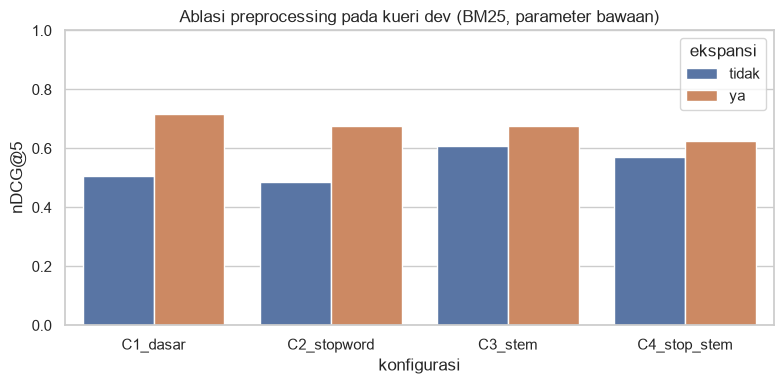

In [18]:
abl_rows = []
for c in AVAILABLE_CONFIGS:
    for qe in [False, True]:
        res = evaluate_system(S("bm25", c, use_qe=qe), DEV)
        abl_rows.append({"konfigurasi": c, "ekspansi": "ya" if qe else "tidak", **res.mean().round(4).to_dict()})
abl = pd.DataFrame(abl_rows)
display(abl)

# Pilih konfigurasi dengan rata-rata nDCG@5 tertinggi (rata-rata tanpa dan dengan ekspansi), hanya dari dev
pilih = abl.groupby("konfigurasi")["nDCG@5"].mean().sort_values(ascending=False)
BEST_CONFIG = pilih.index[0]
print("\nUrutan konfigurasi (nDCG@5 dev):")
print(pilih.round(4).to_string())
print("\nKonfigurasi terpilih:", BEST_CONFIG)

abl.to_csv("outputs/ablasi_preprocessing_dev.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=abl, x="konfigurasi", y="nDCG@5", hue="ekspansi", ax=ax)
ax.set_title("Ablasi preprocessing pada kueri dev (BM25, parameter bawaan)")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("figures/ablasi_preprocessing.png", dpi=150)
plt.show()

### 7b. Tuning parameter BM25 (`k1` dan `b`)

Pencarian grid pada kueri dev dengan konfigurasi terpilih (tanpa ekspansi, agar efek parameter murni). Bila ada nilai yang imbang, dipilih yang paling dekat dengan nilai bawaan (`k1 = 1,5` dan `b = 0,75`) supaya tidak berlebihan menyesuaikan diri pada 15 kueri.

nDCG@5 dev terbaik: 0.6133 | nilai bawaan (1.5, 0.75): 0.6092
Parameter terpilih: k1=1.2, b=0.5


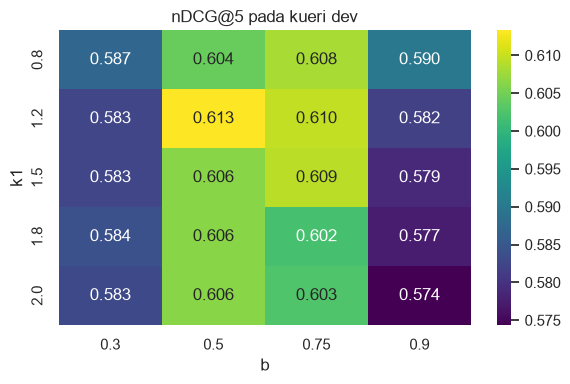

In [19]:
K1_GRID = [0.8, 1.2, 1.5, 1.8, 2.0]
B_GRID = [0.3, 0.5, 0.75, 0.9]

grid = pd.DataFrame(index=K1_GRID, columns=B_GRID, dtype=float)
for k1 in K1_GRID:
    for b in B_GRID:
        grid.loc[k1, b] = mean_metric(S("bm25", BEST_CONFIG, use_qe=False, k1=k1, b=b), DEV)

best_val = grid.values.max()
kandidat = [(k1, b) for k1 in K1_GRID for b in B_GRID if abs(grid.loc[k1, b] - best_val) < 1e-9]
BEST_K1, BEST_B = min(kandidat, key=lambda p: abs(p[0] - 1.5) + abs(p[1] - 0.75))
print(f"nDCG@5 dev terbaik: {best_val:.4f} | nilai bawaan (1.5, 0.75): {grid.loc[1.5, 0.75]:.4f}")
print(f"Parameter terpilih: k1={BEST_K1}, b={BEST_B}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(grid.astype(float), annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("b")
ax.set_ylabel("k1")
ax.set_title("nDCG@5 pada kueri dev")
plt.tight_layout()
plt.savefig("figures/tuning_k1_b.png", dpi=150)
plt.show()
grid.to_csv("outputs/tuning_k1_b_dev.csv")

### 7c. Bobot istilah ekspansi (`qe_weight`)

Istilah hasil ekspansi dibobot lebih kecil daripada kata asli pengguna. Nilai yang diuji: 0,25, 0,5, 0,75, dan 1,0.

In [20]:
QEW_GRID = [0.25, 0.5, 0.75, 1.0]
qew_rows = []
for w in QEW_GRID:
    res = evaluate_system(S("bm25", BEST_CONFIG, use_qe=True, k1=BEST_K1, b=BEST_B, qe_weight=w), DEV)
    qew_rows.append({"qe_weight": w, **res.mean().round(4).to_dict()})
qew = pd.DataFrame(qew_rows)
display(qew)

# Pembanding: tanpa ekspansi (bobot 0)
base_dev = evaluate_system(S("bm25", BEST_CONFIG, use_qe=False, k1=BEST_K1, b=BEST_B), DEV).mean()["nDCG@5"]
print(f"BM25 tanpa ekspansi (dev) nDCG@5 = {base_dev:.4f}")

best_q = qew["nDCG@5"].max()
cands = qew[np.isclose(qew["nDCG@5"], best_q)]["qe_weight"].tolist()
BEST_QEW = min(cands, key=lambda w: abs(w - 0.5))
print("qe_weight terpilih:", BEST_QEW)
qew.to_csv("outputs/tuning_qe_weight_dev.csv", index=False)

,qe_weight,P@5,P@5_ketat,MRR,nDCG@5,Recall@10
0,0.25,0.6667,0.4933,0.9467,0.6699,0.3781
1,0.50,0.6667,0.4800,0.9000,0.6457,0.3863
2,0.75,0.6667,0.4667,0.8889,0.6184,0.3643
3,1.00,0.5733,0.3733,0.8889,0.5422,0.3393


BM25 tanpa ekspansi (dev) nDCG@5 = 0.6133
qe_weight terpilih: 0.25


### 7d. Perbandingan akhir sistem

Empat sistem dibandingkan dengan pengaturan terpilih dari tahap sebelumnya:

1. **TF-IDF**
2. **BM25**
3. **TF-IDF + ekspansi**
4. **BM25 + ekspansi**

**Hasil utama adalah baris `test`**, karena tidak dipakai untuk memilih apa pun. Baris `dev` dan `semua` ditampilkan sebagai pelengkap.

In [21]:
SYSTEMS = {
    "TF-IDF":         S("tfidf", BEST_CONFIG, use_qe=False),
    "BM25":           S("bm25",  BEST_CONFIG, use_qe=False, k1=BEST_K1, b=BEST_B),
    "TF-IDF + QE":    S("tfidf", BEST_CONFIG, use_qe=True, qe_weight=BEST_QEW),
    "BM25 + QE":      S("bm25",  BEST_CONFIG, use_qe=True, k1=BEST_K1, b=BEST_B, qe_weight=BEST_QEW),
}
SUBSETS = {"test": TEST, "dev": DEV, "semua": ALL_Q}

PER_QUERY = {name: {sub: evaluate_system(cfg, qids) for sub, qids in SUBSETS.items()} for name, cfg in SYSTEMS.items()}

tabel = []
for sub in ["test", "dev", "semua"]:
    for name in SYSTEMS:
        m = PER_QUERY[name][sub].mean()
        tabel.append({"subset": sub, "sistem": name, **m.round(4).to_dict()})
HASIL = pd.DataFrame(tabel)
display(HASIL[HASIL.subset == "test"].drop(columns="subset").reset_index(drop=True))
HASIL.to_csv("outputs/hasil_perbandingan.csv", index=False)

# Hasil per kueri (semua) untuk lampiran laporan
pq = pd.concat({name: PER_QUERY[name]["semua"] for name in SYSTEMS}, axis=1)
pq.insert(0, "kueri", [QTEXT[q] for q in pq.index])
pq.to_csv("outputs/hasil_per_kueri.csv")

# Interval kepercayaan bootstrap untuk nDCG@5 (test)
def bootstrap_ci(x, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    means = [rng.choice(x, size=len(x), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

ci_rows = []
for name in SYSTEMS:
    v = PER_QUERY[name]["test"]["nDCG@5"]
    lo, hi = bootstrap_ci(v)
    ci_rows.append({"sistem": name, "nDCG@5 (test)": round(v.mean(), 4), "CI95 bawah": round(lo, 4), "CI95 atas": round(hi, 4)})
display(pd.DataFrame(ci_rows))

,sistem,P@5,P@5_ketat,MRR,nDCG@5,Recall@10
0,TF-IDF,0.5867,0.4267,0.8000,0.6113,0.3867
1,BM25,0.5600,0.4533,0.7167,0.6078,0.3876
2,TF-IDF + QE,0.6000,0.4133,0.8333,0.6171,0.3824
3,BM25 + QE,0.5867,0.4400,0.7917,0.6248,0.3990


,sistem,nDCG@5 (test),CI95 bawah,CI95 atas
0,TF-IDF,0.6113,0.4352,0.7875
1,BM25,0.6078,0.4160,0.7937
2,TF-IDF + QE,0.6171,0.4503,0.7810
3,BM25 + QE,0.6248,0.4439,0.7970


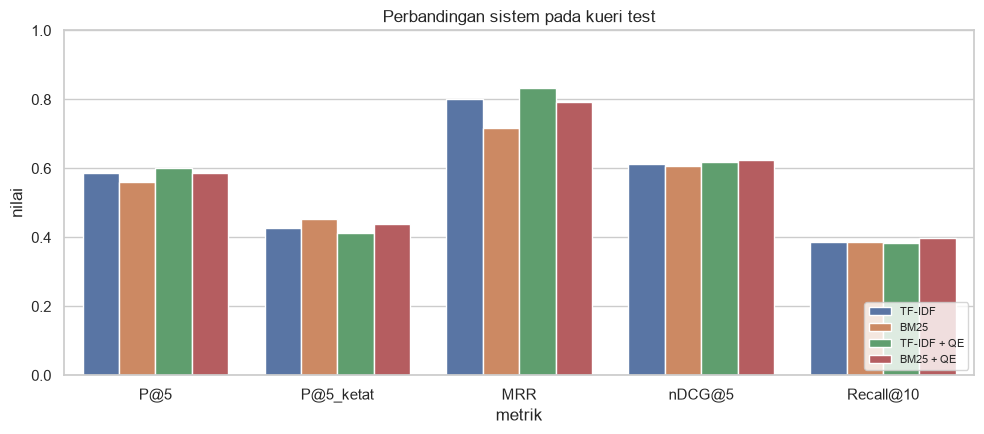

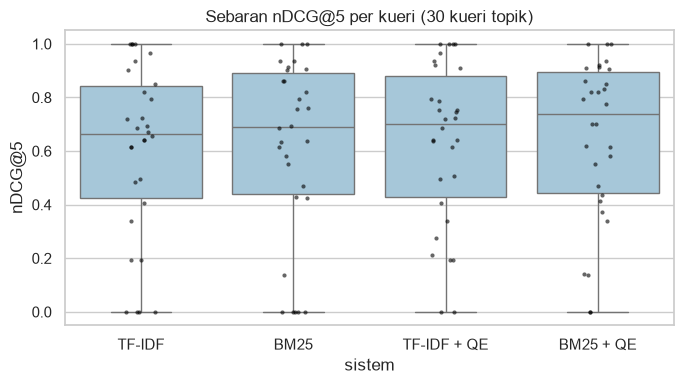

In [22]:
# Grafik: rata-rata metrik pada kueri test
plot_df = HASIL[HASIL.subset == "test"].melt(id_vars=["subset", "sistem"], value_vars=METRICS, var_name="metrik", value_name="nilai")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=plot_df, x="metrik", y="nilai", hue="sistem", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Perbandingan sistem pada kueri test")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("figures/perbandingan_sistem_test.png", dpi=150)
plt.show()

# Grafik: sebaran nDCG@5 per kueri (semua)
box_df = pd.concat([PER_QUERY[n]["semua"]["nDCG@5"].rename("nDCG@5").to_frame().assign(sistem=n) for n in SYSTEMS])
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=box_df, x="sistem", y="nDCG@5", ax=ax, color="#9ecae1")
sns.stripplot(data=box_df, x="sistem", y="nDCG@5", ax=ax, color="black", size=3, alpha=0.6)
ax.set_title("Sebaran nDCG@5 per kueri (30 kueri topik)")
plt.tight_layout()
plt.savefig("figures/sebaran_ndcg_per_kueri.png", dpi=150)
plt.show()

## 8. Uji Signifikansi dan Analisis Error

### 8a. Uji Wilcoxon signed-rank

Selisih rata-rata belum tentu bermakna. Uji **Wilcoxon signed-rank** pada skor per kueri (data berpasangan) menjawab apakah selisih antar sistem konsisten. Dilaporkan pada kueri **test** (tidak bias) dan **semua** (daya uji lebih besar, tetapi 15 kueri di dalamnya dipakai tuning). Kolom `menang/seri/kalah` menunjukkan jumlah kueri tempat sistem pertama lebih baik, sama, dan lebih buruk.

Catatan: dengan 15 kueri, uji ini berdaya rendah. Selisih kecil bisa saja nyata tetapi tidak terdeteksi. Dengan banyak perbandingan sekaligus, nilai p sebaiknya ditafsirkan hati-hati (misalnya koreksi Bonferroni, yaitu membagi 0,05 dengan jumlah uji).

In [23]:
def paired_test(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    d = a - b
    if np.all(d == 0):
        p = 1.0
    else:
        try:
            p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided").pvalue
        except ValueError:
            p = float("nan")
    return {"selisih_rata2": d.mean(), "menang": int((d > 0).sum()), "seri": int((d == 0).sum()),
            "kalah": int((d < 0).sum()), "p_value": p}

PAIRS = [("BM25", "TF-IDF"), ("BM25 + QE", "BM25"), ("BM25 + QE", "TF-IDF"), ("TF-IDF + QE", "TF-IDF")]
wrows = []
for sub in ["test", "semua"]:
    for s1, s2 in PAIRS:
        for met in ["nDCG@5", "P@5", "MRR"]:
            r = paired_test(PER_QUERY[s1][sub][met], PER_QUERY[s2][sub][met])
            wrows.append({"subset": sub, "sistem_1": s1, "sistem_2": s2, "metrik": met, **r})
WIL = pd.DataFrame(wrows)
WIL["signifikan_0.05"] = np.where(WIL.p_value < 0.05, "ya", "tidak")
WIL.to_csv("outputs/uji_wilcoxon.csv", index=False)
display(WIL.round(4))

,subset,sistem_1,sistem_2,metrik,selisih_rata2,menang,seri,kalah,p_value,signifikan_0.05
0,test,BM25,TF-IDF,nDCG@5,-0.0035,3,5,7,0.7989,tidak
1,test,BM25,TF-IDF,P@5,-0.0267,1,12,2,0.5930,tidak
2,test,BM25,TF-IDF,MRR,-0.0833,0,12,3,0.1025,tidak
3,test,BM25 + QE,BM25,nDCG@5,0.0170,2,11,2,0.8539,tidak
4,test,BM25 + QE,BM25,P@5,0.0267,2,13,0,0.1797,tidak
5,test,BM25 + QE,BM25,MRR,0.0750,2,13,0,0.1797,tidak
6,test,BM25 + QE,TF-IDF,nDCG@5,0.0135,4,5,6,0.7989,tidak
7,test,BM25 + QE,TF-IDF,P@5,0.0000,2,12,1,1.0000,tidak
8,test,BM25 + QE,TF-IDF,MRR,-0.0083,1,11,3,0.7150,tidak
9,test,TF-IDF + QE,TF-IDF,nDCG@5,0.0058,2,11,2,1.0000,tidak


### 8b. Pengaruh ekspansi kueri per kueri

Tabel ini menunjukkan kueri mana yang terbantu dan mana yang dirugikan oleh ekspansi. Berguna untuk bagian pembahasan.

In [24]:
qe_delta = (PER_QUERY["BM25 + QE"]["semua"]["nDCG@5"] - PER_QUERY["BM25"]["semua"]["nDCG@5"]).rename("selisih_nDCG@5")
qe_tbl = pd.DataFrame({"kueri": [QTEXT[q] for q in qe_delta.index],
                       "BM25": PER_QUERY["BM25"]["semua"]["nDCG@5"].round(3),
                       "BM25 + QE": PER_QUERY["BM25 + QE"]["semua"]["nDCG@5"].round(3),
                       "selisih": qe_delta.round(3),
                       "topik_kamus_cocok": [", ".join(build_qweights(QTEXT[q], BEST_CONFIG, use_qe=True)[3]) or "(tidak ada)" for q in qe_delta.index]})
display(qe_tbl.sort_values("selisih", ascending=False))
print(f"Kueri terbantu: {(qe_delta > 0).sum()} | tidak berubah: {(qe_delta == 0).sum()} | dirugikan: {(qe_delta < 0).sum()}")

,kueri,BM25,BM25 + QE,selisih,topik_kamus_cocok
query_id,,,,,
Q23,ayat tentang ghibah,0.000,0.437,0.437,ghibah
Q18,ayat tentang sifat sombong,0.000,0.339,0.339,sombong
Q19,ayat tentang utang piutang,0.695,0.908,0.213,utang
Q21,ayat tentang minuman keras,0.000,0.140,0.140,minuman keras
Q09,ayat tentang tawakal,0.638,0.777,0.139,tawakal
Q15,ayat tentang pernikahan,0.636,0.701,0.066,pernikahan
Q12,ayat tentang sedekah,0.762,0.820,0.058,sedekah
Q13,ayat tentang puasa,0.901,0.922,0.021,puasa
Q25,ayat tentang cobaan dan musibah,0.684,0.699,0.015,cobaan


Kueri terbantu: 9 | tidak berubah: 16 | dirugikan: 5


### 8c. Analisis error

Lima kueri dengan nDCG@5 terendah pada sistem terbaik diuraikan: kata yang tidak ada di korpus, topik kamus yang cocok, ayat relevan yang terlewat, dan dugaan penyebab otomatis. **Dugaan otomatis hanya titik awal.** Penjelasan final untuk laporan harus Anda tulis setelah membaca sendiri ayat-ayatnya.

In [25]:
SISTEM_TERBAIK = SYSTEMS["BM25 + QE"]

def diagnose(qid, system=SISTEM_TERBAIK, show=True):
    q = QTEXT[qid]
    qw, qt, extra, matched, _ = build_qweights(q, system["config"], use_qe=system["use_qe"],
                                            qe_weight=system["qe_weight"] if system["qe_weight"] is not None else 0.5)
    idx = get_index(system["config"], system["method"])
    oov = [t for t in qw if t not in idx.vocab]
    ranked = search(q, k=10, return_scores=False, **system)
    rels = QRELS[qid]
    missed = [i for i, g in rels.items() if g == 2 and i not in ranked]
    overlap = [len(set(TOKENS[system["config"]][i - 1]) & set(qw)) for i in missed]
    if not [t for t in qw if t in idx.vocab]:
        sebab = "tidak ada satu pun istilah kueri yang ada di korpus"
    elif missed and sum(1 for o in overlap if o == 0) >= max(1, len(missed) // 2):
        sebab = "ayat relevan memakai istilah lain (kesenjangan kosakata), kamus belum menjembatani"
    elif not matched and missed:
        sebab = "topik belum tercakup kamus ekspansi"
    elif missed:
        sebab = "ayat relevan tersaingi ayat lain yang lebih sering memuat istilah kueri (topik tersebar atau istilah umum)"
    else:
        sebab = "ayat relevan sudah masuk 10 teratas, kekurangan ada pada urutan"
    if show:
        print("=" * 100)
        print(f"{qid} | {q!r} | nDCG@5={ndcg_at_k(ranked, rels, 5):.3f}")
        print(f"  token kueri: {qt} | topik kamus: {matched or '(tidak ada)'} | istilah tak ada di korpus: {oov or '-'}")
        print("  Top-5 hasil:")
        for i in ranked[:5]:
            r = df.iloc[i - 1]
            print(f"    [{rels.get(i, 'belum dinilai')}] {r['surah_nama']} {r['surah_no']}:{r['ayat_no']}  {r['terjemahan'][:90]}")
        print(f"  Ayat bernilai 2 yang terlewat di 10 teratas: {len(missed)}")
        for i in missed[:3]:
            r = df.iloc[i - 1]
            print(f"    {r['surah_nama']} {r['surah_no']}:{r['ayat_no']}  {r['terjemahan'][:90]}")
        print("  Dugaan penyebab:", sebab)
    return sebab

worst = PER_QUERY["BM25 + QE"]["semua"]["nDCG@5"].sort_values().head(5).index.tolist()
err_rows = []
for qid in worst:
    sebab = diagnose(qid)
    err_rows.append({"query_id": qid, "kueri": QTEXT[qid], "nDCG@5": round(PER_QUERY["BM25 + QE"]["semua"].loc[qid, "nDCG@5"], 3), "dugaan_penyebab": sebab})
pd.DataFrame(err_rows).to_csv("outputs/analisis_error.csv", index=False)

Q02 | 'ayat tentang sabar saat menghadapi ujian hidup' | nDCG@5=0.000
  token kueri: ['sabar', 'saat', 'hadap', 'uji', 'hidup'] | topik kamus: ['sabar', 'cobaan'] | istilah tak ada di korpus: -
  Top-5 hasil:
    [belum dinilai] Al-Ahqaf 46:35  Maka bersabarlah kamu seperti orang-orang yang mempunyai keteguhan hati dari rasul-rasul t
    [0] Ar-Rahman 55:46  Dan bagi orang yang takut akan saat menghadap Tuhannya ada dua surga.
    [0] Al-Furqan 25:42  Sesungguhnya hampirlah ia menyesatkan kita dari sembahan-sembahan kita, seandainya kita ti
    [belum dinilai] Ali 'Imran 3:186  Kamu sungguh-sungguh akan diuji terhadap hartamu dan dirimu. Dan (juga) kamu sungguh-sungg
    [belum dinilai] Muhammad 47:31  Dan sesungguhnya Kami benar-benar akan menguji kamu agar Kami mengetahui orang-orang yang 
  Ayat bernilai 2 yang terlewat di 10 teratas: 4
    Al-Baqarah 2:153  Hai orang-orang yang beriman, jadikanlah sabar dan shalat sebagai penolongmu, sesungguhnya
    Al-Baqarah 2:155  Dan sungguh a

### 8d. Cek ayat yang belum dinilai

Ayat yang muncul di 5 teratas tetapi tidak ada di `qrels` dianggap tidak relevan, yang bisa merugikan sistem secara tidak adil. Sel ini menghitung jumlahnya per sistem dan menyimpan daftarnya agar bisa dinilai ulang. Bila jumlahnya besar, nilai ayat-ayat tersebut lalu tambahkan ke `qrels`.

In [26]:
unj_rows, unj_list = [], []
for name, cfg in SYSTEMS.items():
    n_unj = 0
    for qid in ALL_Q:
        top5 = search(QTEXT[qid], k=5, return_scores=False, **cfg)
        for i in top5:
            if i not in QRELS[qid]:
                n_unj += 1
                unj_list.append({"query_id": qid, "kueri": QTEXT[qid], "ayat_id": i,
                                 "ref": f"{df.iloc[i - 1]['surah_nama']} {df.iloc[i - 1]['surah_no']}:{df.iloc[i - 1]['ayat_no']}",
                                 "terjemahan": df.iloc[i - 1]["terjemahan"], "sistem": name, "relevansi": ""})
    unj_rows.append({"sistem": name, "ayat_belum_dinilai_di_top5": n_unj, "dari_total_slot": 5 * len(ALL_Q)})
display(pd.DataFrame(unj_rows))
unj_df = pd.DataFrame(unj_list).drop_duplicates(["query_id", "ayat_id"])
unj_df.to_csv("outputs/ayat_belum_dinilai.csv", index=False, encoding="utf-8-sig")
print(f"Ayat unik belum dinilai: {len(unj_df)} (disimpan di outputs/ayat_belum_dinilai.csv)")
if len(unj_df):
    print("Isi kolom relevansi (0, 1, atau 2) pada berkas itu, tambahkan barisnya ke qrels.csv, lalu jalankan ulang.")

,sistem,ayat_belum_dinilai_di_top5,dari_total_slot
0,TF-IDF,22,150
1,BM25,25,150
2,TF-IDF + QE,28,150
3,BM25 + QE,31,150


Ayat unik belum dinilai: 50 (disimpan di outputs/ayat_belum_dinilai.csv)
Isi kolom relevansi (0, 1, atau 2) pada berkas itu, tambahkan barisnya ke qrels.csv, lalu jalankan ulang.


## 9. Ambang Skor untuk Jawaban "Tidak Ditemukan"

BM25 selalu mengembalikan peringkat selama ada satu kata yang cocok, sehingga kueri di luar topik tetap bisa mendapat ayat. Dibutuhkan **ambang skor**. Skor BM25 mentah bergantung pada panjang kueri dan bobot IDF, jadi dipakai **skor ternormalisasi**: skor teratas dibagi batas atas teoritis skor kueri tersebut (nilainya antara 0 dan 1).

Ambang dipilih pada kueri **dev** dengan kriteria *balanced accuracy* (rata-rata proporsi kueri topik yang dijawab dan proporsi kueri luar topik yang ditolak), lalu diuji pada kueri **test**.

Catatan: jumlah kueri luar topik hanya enam, jadi hasil ini bersifat indikatif. Tambahkan lebih banyak kueri luar topik untuk laporan akhir.

Ambang terbaik pada dev: rentang 0.26 sampai 0.26, dipakai 0.26 (balanced accuracy dev = 0.867)
Pada test: balanced accuracy=0.967 | kueri topik dijawab=0.93 | kueri luar topik ditolak=1.00


,query_id,kueri,in_scope,split,norm_top1
33,Q34,prediksi skor sepak bola malam ini,0,test,0.069
31,Q32,cara install python di laptop,0,test,0.086
30,Q31,resep nasi goreng enak,0,dev,0.107
35,Q36,tips lolos wawancara kerja,0,test,0.131
34,Q35,cara membuat kue bolu,0,dev,0.141
1,Q02,ayat tentang sabar saat menghadapi ujian hidup,1,test,0.162
18,Q19,ayat tentang utang piutang,1,dev,0.197
24,Q25,ayat tentang cobaan dan musibah,1,dev,0.206
6,Q07,ayat tentang menuntut ilmu,1,dev,0.232
32,Q33,harga emas hari ini,0,dev,0.253


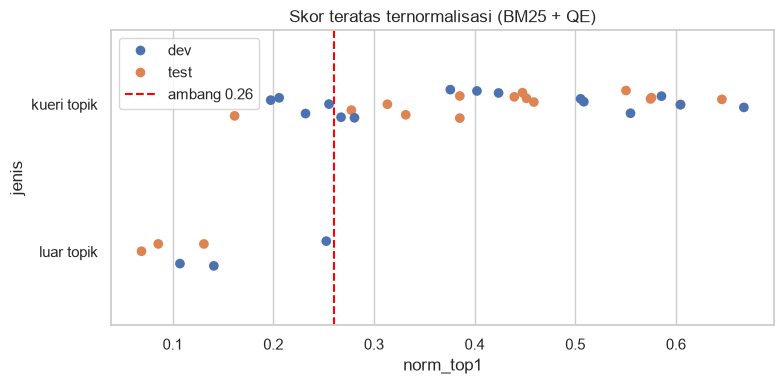

In [27]:
def top_norm_score(qid, system=SISTEM_TERBAIK):
    hasil = search(QTEXT[qid], k=1, **system)
    return hasil[0]["norm_score"] if hasil else 0.0

all_q = pd.concat([queries[queries.in_scope == 1], queries[queries.in_scope == 0]])
sk = pd.DataFrame({"query_id": all_q.query_id, "kueri": all_q["query"], "in_scope": all_q.in_scope,
                   "split": all_q.split, "norm_top1": [top_norm_score(q) for q in all_q.query_id]})

def balanced_acc(sub, t):
    jawab_ok = (sub[sub.in_scope == 1].norm_top1 >= t).mean()
    tolak_ok = (sub[sub.in_scope == 0].norm_top1 < t).mean()
    return (jawab_ok + tolak_ok) / 2, jawab_ok, tolak_ok

dev_sk = sk[sk.split == "dev"]
test_sk = sk[sk.split == "test"]
grid_t = np.round(np.arange(0.0, 0.81, 0.01), 2)
scan = pd.DataFrame([{"ambang": t, **dict(zip(["balanced_acc", "dijawab_benar", "ditolak_benar"], balanced_acc(dev_sk, t)))} for t in grid_t])
best_ba = scan.balanced_acc.max()
best_ts = scan[np.isclose(scan.balanced_acc, best_ba)].ambang.tolist()
THRESHOLD = float(np.median(best_ts))
print(f"Ambang terbaik pada dev: rentang {min(best_ts)} sampai {max(best_ts)}, dipakai {THRESHOLD} (balanced accuracy dev = {best_ba:.3f})")

ba, jb, tb = balanced_acc(test_sk, THRESHOLD)
print(f"Pada test: balanced accuracy={ba:.3f} | kueri topik dijawab={jb:.2f} | kueri luar topik ditolak={tb:.2f}")
display(sk.sort_values("norm_top1").round(3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(data=sk.assign(jenis=sk.in_scope.map({1: "kueri topik", 0: "luar topik"})), x="norm_top1", y="jenis", hue="split", ax=ax, size=7)
ax.axvline(THRESHOLD, color="red", linestyle="--", label=f"ambang {THRESHOLD}")
ax.set_title("Skor teratas ternormalisasi (BM25 + QE)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/ambang_skor.png", dpi=150)
plt.show()
sk.to_csv("outputs/skor_ambang.csv", index=False)

Skor ternormalisasi memisahkan kueri luar topik dengan baik pada contoh ini, tetapi **tidak sempurna**. Ada kueri topik yang skornya rendah (misalnya kueri yang kata utamanya tidak ada di kamus) dan kueri luar topik yang skornya cukup tinggi (misalnya `harga emas hari ini`, karena kata `emas` memang ada di Al-Qur'an). Satu ambang skor adalah pengaman pertama, bukan pengaman tunggal. Pengaman kedua adalah aturan pada prompt RAG di bagian berikut.

## 10. Komponen RAG: Prompt, Guardrail, Validasi, dan Rubrik Chatbot

Prinsip rancangan:

1. **Ayat selalu ditampilkan langsung dari tabel data**, bukan ditulis ulang oleh model bahasa. Teks Arab bahkan tidak dikirim ke model.
2. Model bahasa hanya menerima **terjemahan ayat hasil retrieval** dan hanya diminta merangkum keterkaitan ayat dengan pertanyaan.
3. Empat lapis pengaman:
   - **Ambang skor** (bagian 9): bila tidak ada ayat yang cukup cocok, jawab "tidak ditemukan".
   - **Penolakan permintaan hukum atau fatwa**: pertanyaan seperti "apakah X haram?" tidak dijawab dengan hukum.
   - **System prompt ketat** yang melarang tafsir dan hukum.
   - **Validasi keluaran dengan kode**: setiap rujukan `surah:ayat` pada jawaban harus ada dalam daftar ayat hasil retrieval, tidak boleh ada teks Arab, dan tidak boleh ada frasa tafsir atau hukum. Bila gagal, dicoba ulang satu kali, lalu memakai ringkasan cadangan yang disusun tanpa model bahasa.

Notebook ini berjalan penuh **tanpa kunci API** memakai ringkasan cadangan (offline). Untuk memakai model bahasa sungguhan, isi `LLM_FN` di sel berikut.

In [28]:
BEST_SYSTEM = SYSTEMS["BM25 + QE"]

SYSTEM_PROMPT = """Kamu adalah AyatQu, alat bantu pencarian ayat Al-Qur'an berdasarkan topik.

Aturan yang tidak boleh dilanggar:
1. Gunakan HANYA ayat yang diberikan pada bagian KONTEKS. Jangan menambahkan ayat lain dan jangan mengutip dari ingatanmu.
2. Tugasmu hanya menjelaskan secara singkat (2 sampai 4 kalimat) mengapa ayat-ayat tersebut berkaitan dengan pertanyaan pengguna, berdasarkan isi terjemahan yang diberikan.
3. Jangan menafsirkan, jangan menyimpulkan makna di luar teks terjemahan, jangan menyebut pendapat ulama atau ahli tafsir.
4. Jangan memberi hukum, fatwa, atau penilaian halal, haram, wajib, dosa, dan sejenisnya.
5. Rujuk setiap ayat dengan format (QS. Nama-Surah nomor-surah:nomor-ayat), contoh (QS. Al-Baqarah 2:153).
6. Jangan menulis teks Arab.
7. Akhiri dengan satu kalimat yang mengarahkan pengguna ke tafsir resmi atau ulama untuk pemahaman lebih lanjut.
8. Gunakan bahasa Indonesia yang sopan dan sederhana."""

REFUSAL_FATWA = ("AyatQu adalah alat bantu pencarian ayat dan tidak memberikan hukum atau fatwa. "
                 "Berikut ayat-ayat yang berkaitan dengan topik pertanyaanmu. "
                 "Untuk hukumnya, silakan bertanya kepada ulama atau lembaga fatwa yang terpercaya.")
NOT_FOUND = "Maaf, AyatQu tidak menemukan ayat yang sesuai dengan pertanyaan tersebut. Coba gunakan kata kunci topik yang lain."
FOOTNOTE = "AyatQu adalah alat bantu pencarian, bukan sumber tafsir atau fatwa."

def is_ruling_request(q):
    """Heuristik awal untuk mendeteksi permintaan hukum atau fatwa. Perlu diperbaiki bila dipakai sungguhan."""
    t = clean_text(q)
    explicit_ayat = bool(re.match(r"^(ayat|surah|surat|carikan ayat|cari ayat)\b", t))
    strong = re.search(r"\b(apakah|apa)\b.*\b(halal|haram|boleh|dosa|wajib|makruh|sah|batal)\b", t) \
        or re.search(r"\b(halal atau haram|boleh atau tidak|boleh tidak|fatwa)\b", t)
    weak = re.search(r"\b(hukum|hukumnya|bolehkah|haramkah|halalkah|wajibkah)\b", t)
    return bool(strong) or (bool(weak) and not explicit_ayat)

RULING_TESTS = [("apakah rokok haram", True), ("hukum bermain judi online", True), ("bolehkah makan kepiting", True),
                ("halal atau haram bunga bank", True), ("apakah riba itu dosa", True),
                ("ayat tentang riba", False), ("ayat tentang minuman keras", False), ("ayat tentang hukum waris", False),
                ("ayat tentang halal dan haram", False), ("ayat tentang sabar", False)]
for q, harapan in RULING_TESTS:
    assert is_ruling_request(q) == harapan, f"Deteksi permintaan hukum salah untuk: {q}"
print("Uji deteksi permintaan hukum lulus:", len(RULING_TESTS), "kasus.")

def ref_label(i):
    r = df.iloc[i - 1]
    return f"QS. {r['surah_nama']} {r['surah_no']}:{r['ayat_no']}"

def build_context(hits):
    return "\n".join(f"[{df.iloc[h['id'] - 1]['surah_no']}:{df.iloc[h['id'] - 1]['ayat_no']}] ({df.iloc[h['id'] - 1]['surah_nama']}) {df.iloc[h['id'] - 1]['terjemahan']}" for h in hits)

def build_user_prompt(query, hits):
    return f"Pertanyaan pengguna: {query}\n\nKONTEKS (terjemahan ayat hasil pencarian):\n{build_context(hits)}\n\nTulis ringkasan keterkaitan sesuai aturan."

_CITE = re.compile(r"(\d{1,3})\s*:\s*(\d{1,3})(?:\s*[-\u2013]\s*(\d{1,3}))?")
_BANNED = re.compile(r"\b(menurut (para )?(ulama|ahli tafsir|mufassir|tafsir)|tafsirnya|hukumnya|berdosa|haram hukumnya|halal hukumnya|wajib hukumnya|fatwa)\b", re.I)
_ARAB = re.compile(r"[\u0600-\u06FF]")

def extract_citations(text):
    refs = set()
    for m in _CITE.finditer(text):
        s, a1 = int(m.group(1)), int(m.group(2))
        a2 = int(m.group(3)) if m.group(3) else a1
        for a in range(a1, max(a1, a2) + 1):
            refs.add((s, a))
    return refs

def validate_answer(text, hits):
    allowed = {(int(df.iloc[h["id"] - 1]["surah_no"]), int(df.iloc[h["id"] - 1]["ayat_no"])) for h in hits}
    cited = extract_citations(text)
    di_luar = sorted(cited - allowed)
    flagged = _BANNED.findall(text)
    out = {"rujukan_di_jawaban": sorted(cited), "rujukan_di_luar_hasil": di_luar,
           "ada_frasa_tafsir_hukum": bool(flagged), "ada_teks_arab": bool(_ARAB.search(text)),
           "ada_rujukan": bool(cited)}
    out["lolos"] = (not di_luar) and (not flagged) and (not out["ada_teks_arab"])
    return out

def offline_summary(query, hits):
    """Ringkasan cadangan tanpa model bahasa. Hanya menyebut ayat yang ditemukan, tanpa tafsir."""
    topik = " ".join(preprocess(query, is_query=True)) or "topik yang ditanyakan"
    refs = ", ".join(f"({ref_label(h['id'])})" for h in hits)
    return (f"Ayat-ayat berikut memuat kata-kata yang berkaitan dengan \"{topik}\": {refs}. "
            "Silakan membaca terjemahan lengkapnya pada kartu ayat. "
            "Untuk pemahaman lebih lanjut, rujuklah tafsir resmi atau ulama.")

def ayatqu_answer(query, summarizer=None, k=5, max_retry=1):
    summarizer = summarizer or offline_summary
    hits = search(query, k=k, **BEST_SYSTEM)
    layak = bool(hits) and hits[0]["norm_score"] >= THRESHOLD
    res = {"query": query, "status": None, "hits": hits if layak else [], "ringkasan": "", "validasi": None}
    if is_ruling_request(query):
        res.update(status="ditolak_fatwa", ringkasan=REFUSAL_FATWA if layak else REFUSAL_FATWA + " (Tidak ada ayat yang cukup cocok untuk ditampilkan.)")
        return res
    if not layak:
        res.update(status="tidak_ditemukan", ringkasan=NOT_FOUND)
        return res
    for _ in range(max_retry + 1):
        teks = summarizer(query, hits)
        v = validate_answer(teks, hits)
        if v["lolos"]:
            res.update(status="ok", ringkasan=teks, validasi=v)
            return res
    teks = offline_summary(query, hits)
    res.update(status="ringkasan_cadangan", ringkasan=teks, validasi=validate_answer(teks, hits))
    return res

def tampilkan(res):
    print("=" * 90)
    print("Pertanyaan:", res["query"], "| status:", res["status"])
    for h in res["hits"]:
        r = df.iloc[h["id"] - 1]
        print(f"\n[{r['surah_nama']} {r['surah_no']}:{r['ayat_no']}]")
        if r["teks_arab"]:
            print("  ", r["teks_arab"])
        print("  ", r["terjemahan"])
    print("\nRingkasan:", res["ringkasan"])
    print(FOOTNOTE)

# Hubungkan model bahasa sungguhan di sini (opsional).
# Contoh dengan Anthropic SDK (pip install anthropic, lalu set ANTHROPIC_API_KEY di environment):
#
#   from anthropic import Anthropic
#   client = Anthropic()
#   MODEL = os.environ.get("AYATQU_MODEL", "claude-haiku-5-5")   # periksa nama model terbaru di dokumentasi
#   def LLM_FN(system, user):
#       msg = client.messages.create(model=MODEL, max_tokens=400, temperature=0, system=system,
#                                    messages=[{"role": "user", "content": user}])
#       return msg.content[0].text
LLM_FN = None   # None berarti memakai ringkasan cadangan offline

def make_summarizer(llm_fn):
    if llm_fn is None:
        return offline_summary
    return lambda query, hits: llm_fn(SYSTEM_PROMPT, build_user_prompt(query, hits))

SUMMARIZER = make_summarizer(LLM_FN)

for q in ["ayat tentang sabar", "ayat tentang berbakti kepada orang tua", "apakah rokok haram", "resep nasi goreng enak"]:
    tampilkan(ayatqu_answer(q, SUMMARIZER, k=3))

Uji deteksi permintaan hukum lulus: 10 kasus.
Pertanyaan: ayat tentang sabar | status: ok

[Al-Ma'arij 70:5]
   فَٱصْبِرْ صَبْرًا جَمِيلًا
   Maka bersabarlah kamu dengan sabar yang baik.

[Al-Baqarah 2:153]
   يَـٰٓأَيُّهَا ٱلَّذِينَ ءَامَنُوا۟ ٱسْتَعِينُوا۟ بِٱلصَّبْرِ وَٱلصَّلَوٰةِ ۚ إِنَّ ٱللَّهَ مَعَ ٱلصَّـٰبِرِينَ
   Hai orang-orang yang beriman, jadikanlah sabar dan shalat sebagai penolongmu, sesungguhnya Allah beserta orang-orang yang sabar.

[Ali 'Imran 3:200]
   يَـٰٓأَيُّهَا ٱلَّذِينَ ءَامَنُوا۟ ٱصْبِرُوا۟ وَصَابِرُوا۟ وَرَابِطُوا۟ وَٱتَّقُوا۟ ٱللَّهَ لَعَلَّكُمْ تُفْلِحُونَ
   Hai orang-orang yang beriman, bersabarlah kamu dan kuatkanlah kesabaranmu dan tetaplah bersiap siaga (di perbatasan negerimu) dan bertakwalah kepada Allah, supaya kamu beruntung.

Ringkasan: Ayat-ayat berikut memuat kata-kata yang berkaitan dengan "sabar": (QS. Al-Ma'arij 70:5), (QS. Al-Baqarah 2:153), (QS. Ali 'Imran 3:200). Silakan membaca terjemahan lengkapnya pada kartu ayat. Untuk pemahaman lebih

### 10b. Uji guardrail dengan jawaban model bahasa tiruan

Empat model tiruan dipakai untuk memastikan validator bekerja: satu menjawab benar, satu mengutip ayat di luar hasil, satu memberi hukum, dan satu menulis teks Arab. Hanya yang pertama boleh lolos. Tiga lainnya harus memicu ringkasan cadangan.

In [29]:
_hits_uji = search("ayat tentang sabar", k=3, **BEST_SYSTEM)
_ref0 = ref_label(_hits_uji[0]["id"])

def llm_baik(q, h):
    return f"Ayat ini berkaitan dengan pertanyaan karena terjemahannya menyebut sabar ({ref_label(h[0]['id'])}). Untuk pemahaman lebih lanjut, rujuklah tafsir resmi."
def llm_rujukan_palsu(q, h):
    return f"Lihat juga (QS. Al-Baqarah 2:999) dan {ref_label(h[0]['id'])}."
def llm_hukum(q, h):
    return f"({ref_label(h[0]['id'])}) Hukumnya wajib bagi setiap muslim."
def llm_arab(q, h):
    return f"({ref_label(h[0]['id'])}) \u0627\u0644\u0635\u0628\u0631 \u0645\u0641\u062a\u0627\u062d \u0627\u0644\u0641\u0631\u062c"

hasil_uji = {}
for nama, fn in [("baik", llm_baik), ("rujukan_palsu", llm_rujukan_palsu), ("hukum", llm_hukum), ("arab", llm_arab)]:
    r = ayatqu_answer("ayat tentang sabar", fn, k=3)
    hasil_uji[nama] = r["status"]
print(hasil_uji)
assert hasil_uji == {"baik": "ok", "rujukan_palsu": "ringkasan_cadangan", "hukum": "ringkasan_cadangan", "arab": "ringkasan_cadangan"}
assert ayatqu_answer("resep nasi goreng enak")["status"] == "tidak_ditemukan"
assert ayatqu_answer("apakah rokok haram")["status"] == "ditolak_fatwa"
print("Semua uji guardrail lulus.")

{'baik': 'ok', 'rujukan_palsu': 'ringkasan_cadangan', 'hukum': 'ringkasan_cadangan', 'arab': 'ringkasan_cadangan'}
Semua uji guardrail lulus.


### 10c. Rubrik evaluasi chatbot

Rubrik empat butir (jawaban ya atau tidak) dijalankan pada seluruh kueri uji:

| Butir | Cara menilai |
|---|---|
| R1. Semua ayat yang disebut berasal dari hasil retrieval | **Otomatis** dengan kode |
| R2. Tidak ada tafsir atau hukum tambahan | **Otomatis sebagian** (deteksi frasa terlarang), lalu **dicek manual** |
| R3. Ringkasan sesuai isi terjemahan | **Manual** oleh Anda atau validator |
| R4. Penolakan bekerja (kueri luar topik dan permintaan hukum) | Otomatis menghitung status, lalu manual memastikan kewajarannya |

Sel di bawah membuat lembar rubrik `outputs/chatbot_rubrik.csv`. **Jalankan dengan `LLM_FN` yang sudah diisi** agar yang diuji adalah model bahasa sungguhan. Dengan ringkasan cadangan offline, R1 dan R2 otomatis 100 persen karena teksnya disusun oleh template, jadi angka itu tidak membuktikan apa pun tentang model bahasa.

In [30]:
rubrik_q = [(qid, QTEXT[qid], "topik") for qid in ALL_Q] \
         + [(qid, QTEXT[qid], "luar topik") for qid in OOS_DEV + OOS_TEST] \
         + [(f"F{i + 1:02d}", q, "minta hukum") for i, q in enumerate(["apakah rokok haram", "hukum bermain judi online", "bolehkah makan kepiting", "apakah riba itu dosa"])]

rub_rows = []
for qid, q, jenis in rubrik_q:
    r = ayatqu_answer(q, SUMMARIZER, k=5)
    v = r["validasi"] or {}
    rub_rows.append({"id": qid, "kueri": q, "jenis": jenis, "status": r["status"], "jumlah_ayat_ditampilkan": len(r["hits"]),
                     "R1_rujukan_di_luar_hasil": len(v.get("rujukan_di_luar_hasil", [])) if v else "",
                     "R2_frasa_tafsir_hukum_terdeteksi": ("ya" if v.get("ada_frasa_tafsir_hukum") else "tidak") if v else "",
                     "ringkasan": r["ringkasan"],
                     "R2_cek_manual_ada_tafsir_hukum (ya/tidak)": "",
                     "R3_ringkasan_sesuai_terjemahan (ya/tidak)": "",
                     "R4_penolakan_wajar (ya/tidak)": ""})
RUB = pd.DataFrame(rub_rows)
RUB.to_csv("outputs/chatbot_rubrik.csv", index=False, encoding="utf-8-sig")

dijawab = RUB[RUB.status.isin(["ok", "ringkasan_cadangan"])]
print(f"Jumlah kueri: {len(RUB)} | dijawab: {len(dijawab)}")
print(f"R1 otomatis: {(dijawab.R1_rujukan_di_luar_hasil == 0).mean() * 100:.0f}% jawaban hanya merujuk ayat hasil retrieval")
print(f"R2 otomatis: {(dijawab.R2_frasa_tafsir_hukum_terdeteksi == 'tidak').mean() * 100:.0f}% jawaban bebas frasa tafsir atau hukum")
print("Status per jenis kueri:")
display(pd.crosstab(RUB.jenis, RUB.status))
print("Lembar rubrik disimpan: outputs/chatbot_rubrik.csv (isi kolom R2, R3, R4 secara manual)")
if LLM_FN is None:
    print("CATATAN: LLM_FN kosong, jadi angka R1 dan R2 di atas berasal dari ringkasan template, bukan model bahasa.")

Jumlah kueri: 40 | dijawab: 25
R1 otomatis: 100% jawaban hanya merujuk ayat hasil retrieval
R2 otomatis: 100% jawaban bebas frasa tafsir atau hukum
Status per jenis kueri:


status,ditolak_fatwa,ok,tidak_ditemukan
jenis,,,
luar topik,0,0,6
minta hukum,4,0,0
topik,0,25,5


Lembar rubrik disimpan: outputs/chatbot_rubrik.csv (isi kolom R2, R3, R4 secara manual)
CATATAN: LLM_FN kosong, jadi angka R1 dan R2 di atas berasal dari ringkasan template, bukan model bahasa.


## 11. Ekspor Konfigurasi untuk Aplikasi Streamlit

Semua pilihan terbaik disimpan ke `models/best_config.json`. Aplikasi nanti hanya membaca berkas ini, membangun indeks dari `quran_master.csv`, dan memakai fungsi yang sama.

In [31]:
test_res = HASIL[HASIL.subset == "test"].set_index("sistem")[METRICS].to_dict(orient="index")
config_out = {
    "preprocessing_config": BEST_CONFIG,
    "metode": "bm25",
    "k1": BEST_K1,
    "b": BEST_B,
    "ekspansi_kueri": True,
    "qe_weight": BEST_QEW,
    "ambang_skor_ternormalisasi": THRESHOLD,
    "top_k": 5,
    "sastrawi_dipakai": bool(CONFIGS[BEST_CONFIG]["stem"]),
    "stopword_dipakai": bool(CONFIGS[BEST_CONFIG]["stop"]),
    "file_qrels": QRELS_FILE,
    "status_qrels": "tervalidasi manusia" if "final" in QRELS_FILE else "DRAF AI, belum divalidasi manusia",
    "hasil_test": {k: {m: round(float(x), 4) for m, x in v.items()} for k, v in test_res.items()},
}
Path("models/best_config.json").write_text(json.dumps(config_out, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(config_out, ensure_ascii=False, indent=2))

print("\nBerkas keluaran:")
for p in sorted(list(Path("outputs").glob("*")) + list(Path("figures").glob("*")) + [Path("models/best_config.json"), Path("expansion_dict.json")]):
    print("  ", p)

{
  "preprocessing_config": "C3_stem",
  "metode": "bm25",
  "k1": 1.2,
  "b": 0.5,
  "ekspansi_kueri": true,
  "qe_weight": 0.25,
  "ambang_skor_ternormalisasi": 0.26,
  "top_k": 5,
  "sastrawi_dipakai": true,
  "stopword_dipakai": false,
  "file_qrels": "data/eval/qrels.csv",
  "status_qrels": "DRAF AI, belum divalidasi manusia",
  "hasil_test": {
    "TF-IDF": {
      "P@5": 0.5867,
      "P@5_ketat": 0.4267,
      "MRR": 0.8,
      "nDCG@5": 0.6113,
      "Recall@10": 0.3867
    },
    "BM25": {
      "P@5": 0.56,
      "P@5_ketat": 0.4533,
      "MRR": 0.7167,
      "nDCG@5": 0.6078,
      "Recall@10": 0.3876
    },
    "TF-IDF + QE": {
      "P@5": 0.6,
      "P@5_ketat": 0.4133,
      "MRR": 0.8333,
      "nDCG@5": 0.6171,
      "Recall@10": 0.3824
    },
    "BM25 + QE": {
      "P@5": 0.5867,
      "P@5_ketat": 0.44,
      "MRR": 0.7917,
      "nDCG@5": 0.6248,
      "Recall@10": 0.399
    }
  }
}

Berkas keluaran:
   expansion_dict.json
   figures\.gitkeep
   figures\ablasi_p

## Daftar Periksa Sebelum Menulis Laporan

1. **Validasi kunci jawaban.** `qrels.csv` bawaan adalah draf AI. Serahkan `data/eval/qrels_lembar_validasi.csv` ke dosen atau ustaz (idealnya dua penilai), hitung Cohen's kappa dengan `finalize_qrels_from_validation()`, lalu jalankan ulang seluruh notebook dengan `qrels_final.csv`. **Angka hasil di laporan hanya boleh diambil setelah langkah ini.**
2. **Validasi kamus ekspansi.** Kirim `expansion_dict.json` dan `data/eval/expansion_dict_report.csv` ke validator.
3. **Pasang PySastrawi** agar konfigurasi stemming (C3 dan C4) ikut berjalan, lalu jalankan ulang. Hasil ablasi dan konfigurasi terpilih bisa berubah.
4. **Cek ayat belum dinilai** (`outputs/ayat_belum_dinilai.csv`). Nilai dan tambahkan ke qrels bila jumlahnya banyak.
5. **Tambah kueri luar topik** (minimal 15 sampai 20) agar evaluasi ambang skor lebih meyakinkan.
6. **Jalankan rubrik chatbot dengan model bahasa sungguhan** (`LLM_FN`), lalu isi kolom manual R2, R3, R4.
7. **Tulis keterbatasan** dengan jujur: jumlah kueri kecil (uji statistik berdaya rendah), pooling dibuat dari sistem yang diuji (cenderung menguntungkan BM25 + ekspansi), satu terjemahan, kamus dibuat manual, sistem bukan sumber tafsir atau fatwa.
8. **Cantumkan sumber data**: Tanzil.net (teks Uthmani dan terjemahan Indonesia dari Kementerian Agama RI), tanggal akses, dan ketentuan lisensinya.
9. **Verifikasi setiap rujukan pustaka** sebelum dikutip. Rujukan awal: Manning, Raghavan, dan Schütze (2008) *Introduction to Information Retrieval*, Robertson dan Zaragoza (2009) tentang BM25, Järvelin dan Kekäläinen (2002) tentang nDCG, Tala (2003) tentang stemming bahasa Indonesia, Lewis dkk. (2020) tentang RAG. Cari sendiri judul penelitian terdahulu tentang pencarian Al-Qur'an lewat Google Scholar atau Garuda, lalu cek asal-usulnya.